# Retrained Session Networks

Load a network retrained on P2 and A2, then inspect the retraining loss of each session separately. P2 inputs were initialized from the original P1 inputs, and A2 inputs from A1.

Each loss value is the session's mean squared error across neurons, time bins, and the trained conditions, recorded before the optimizer update. Retraining histories start at step 0.


In [48]:
%matplotlib inline

import importlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from utils import experiment_param

import _8_LatentNetwork as ln
importlib.reload(ln)

dirpath = '/Users/kimchm/Documents/KimNiNature2024/MatConverted2Python/' 
par = experiment_param.ExperimentParam(dirpath)
relearntime_sorted = par.relearn_time[par.sorted_indices_by_relearn_speed]

# Select the retrained network.
training_path = Path(ln.TRAINING_DATA_PATH)
device = 'cpu'
dataset_id = '0'
n_input_components = 1
recurrent_type = 'lowrank'  # 'fullconn' or 'lowrank'
recurrent_rank = 10        # None for fullconn
retrained_conditions = ('P2', 'A2')

source_checkpoint_path = Path(ln.latent_network_checkpoint_path(
    dataset_id=dataset_id,
    n_input_components=n_input_components,
    recurrent_type=recurrent_type,
    recurrent_rank=recurrent_rank,
    training_path=training_path,
))
checkpoint_path = Path(ln.retrained_network_checkpoint_path(
    source_checkpoint=source_checkpoint_path,
    conditions=retrained_conditions,
    recurrent_type=recurrent_type,
))
# For a custom filename, replace checkpoint_path with Path('path/to/checkpoint.pt').
print('retrained checkpoint:', checkpoint_path)
print('exists:', checkpoint_path.exists())

print('source checkpoint:', source_checkpoint_path)
print('exists:', source_checkpoint_path.exists())
print('training path:', training_path)

retrained checkpoint: data/training/recurrent/lowrank/latent_network_Dataset0_In1_Rank10_lowrank_retrained_P2_A2.pt
exists: True
source checkpoint: data/training/recurrent/lowrank/latent_network_Dataset0_In1_Rank10_lowrank.pt
exists: True
training path: data/training/recurrent


## Load the source network

In [49]:
results_src = ln.load_latent_network(
    checkpoint_path=source_checkpoint_path,
    training_path=training_path,
    device=device,
)
rnn_src = results_src['rnn']
rnn_src.eval()
dataset = results_src['dataset']
n_sessions = rnn_src.n_sessions
loss_history_src = results_src['loss_history']
loss_history_by_session_src = results_src['loss_history_by_session']

print('conditions:', rnn_src.conditions)
print('sessions:', rnn_src.session_ids)
print('training steps:', len(loss_history_src))


conditions: ('P1', 'A1')
sessions: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32)
training steps: 5000


## Load the retrained network

The settings above select the checkpoint ending in `_retrained_P2_A2.pt`. Its saved configuration determines the network architecture and trained conditions. `results` contains the restored network, neural dataset, aggregate loss, and per-session loss histories.


In [30]:
results = ln.load_latent_network(
    checkpoint_path=checkpoint_path,
    training_path=training_path,
    device=device,
)
rnn = results['rnn']
rnn.eval()
dataset = results['dataset']
n_sessions = rnn.n_sessions
loss_history = results['loss_history']
loss_history_by_session = results['loss_history_by_session']

missing_sessions = [
    fx for fx in rnn.session_ids
    if len(loss_history_by_session.get(fx, ())) == 0
]
if missing_sessions:
    raise ValueError(
        f'No saved loss history for sessions {missing_sessions}. '
        'Use a checkpoint trained with per-session loss recording.'
    )

print('conditions:', rnn.conditions)
print('sessions:', rnn.session_ids)
print('retraining steps:', len(loss_history))


conditions: ('P2', 'A2')
sessions: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32)
retraining steps: 5000


In [31]:
# Load one CD dot product per session for the selected dataset.
CDdotproduct = np.load(
    training_path / f"CDdotproduct{dataset['id']}.npy",
    allow_pickle=False,
)
print('CDdotproduct shape:', CDdotproduct.shape)
# Access a session's value with CDdotproduct[fx].


CDdotproduct shape: (33,)


In [32]:
# Run the training-data generator first to save neuron_fraction{dataset_id}.npy.
neuron_fraction = np.load(
    training_path / f"neuron_fraction{dataset['id']}.npy",
    allow_pickle=False,
)
print('neuron_fraction shape:', neuron_fraction.shape)
# Access a session's fraction with neuron_fraction[fx].


neuron_fraction shape: (33,)


## Retraining loss by session

Each subplot shows one session, with its own vertical scale. 
The numeric history for session `fx` is available as `loss_history_by_session[fx]`.


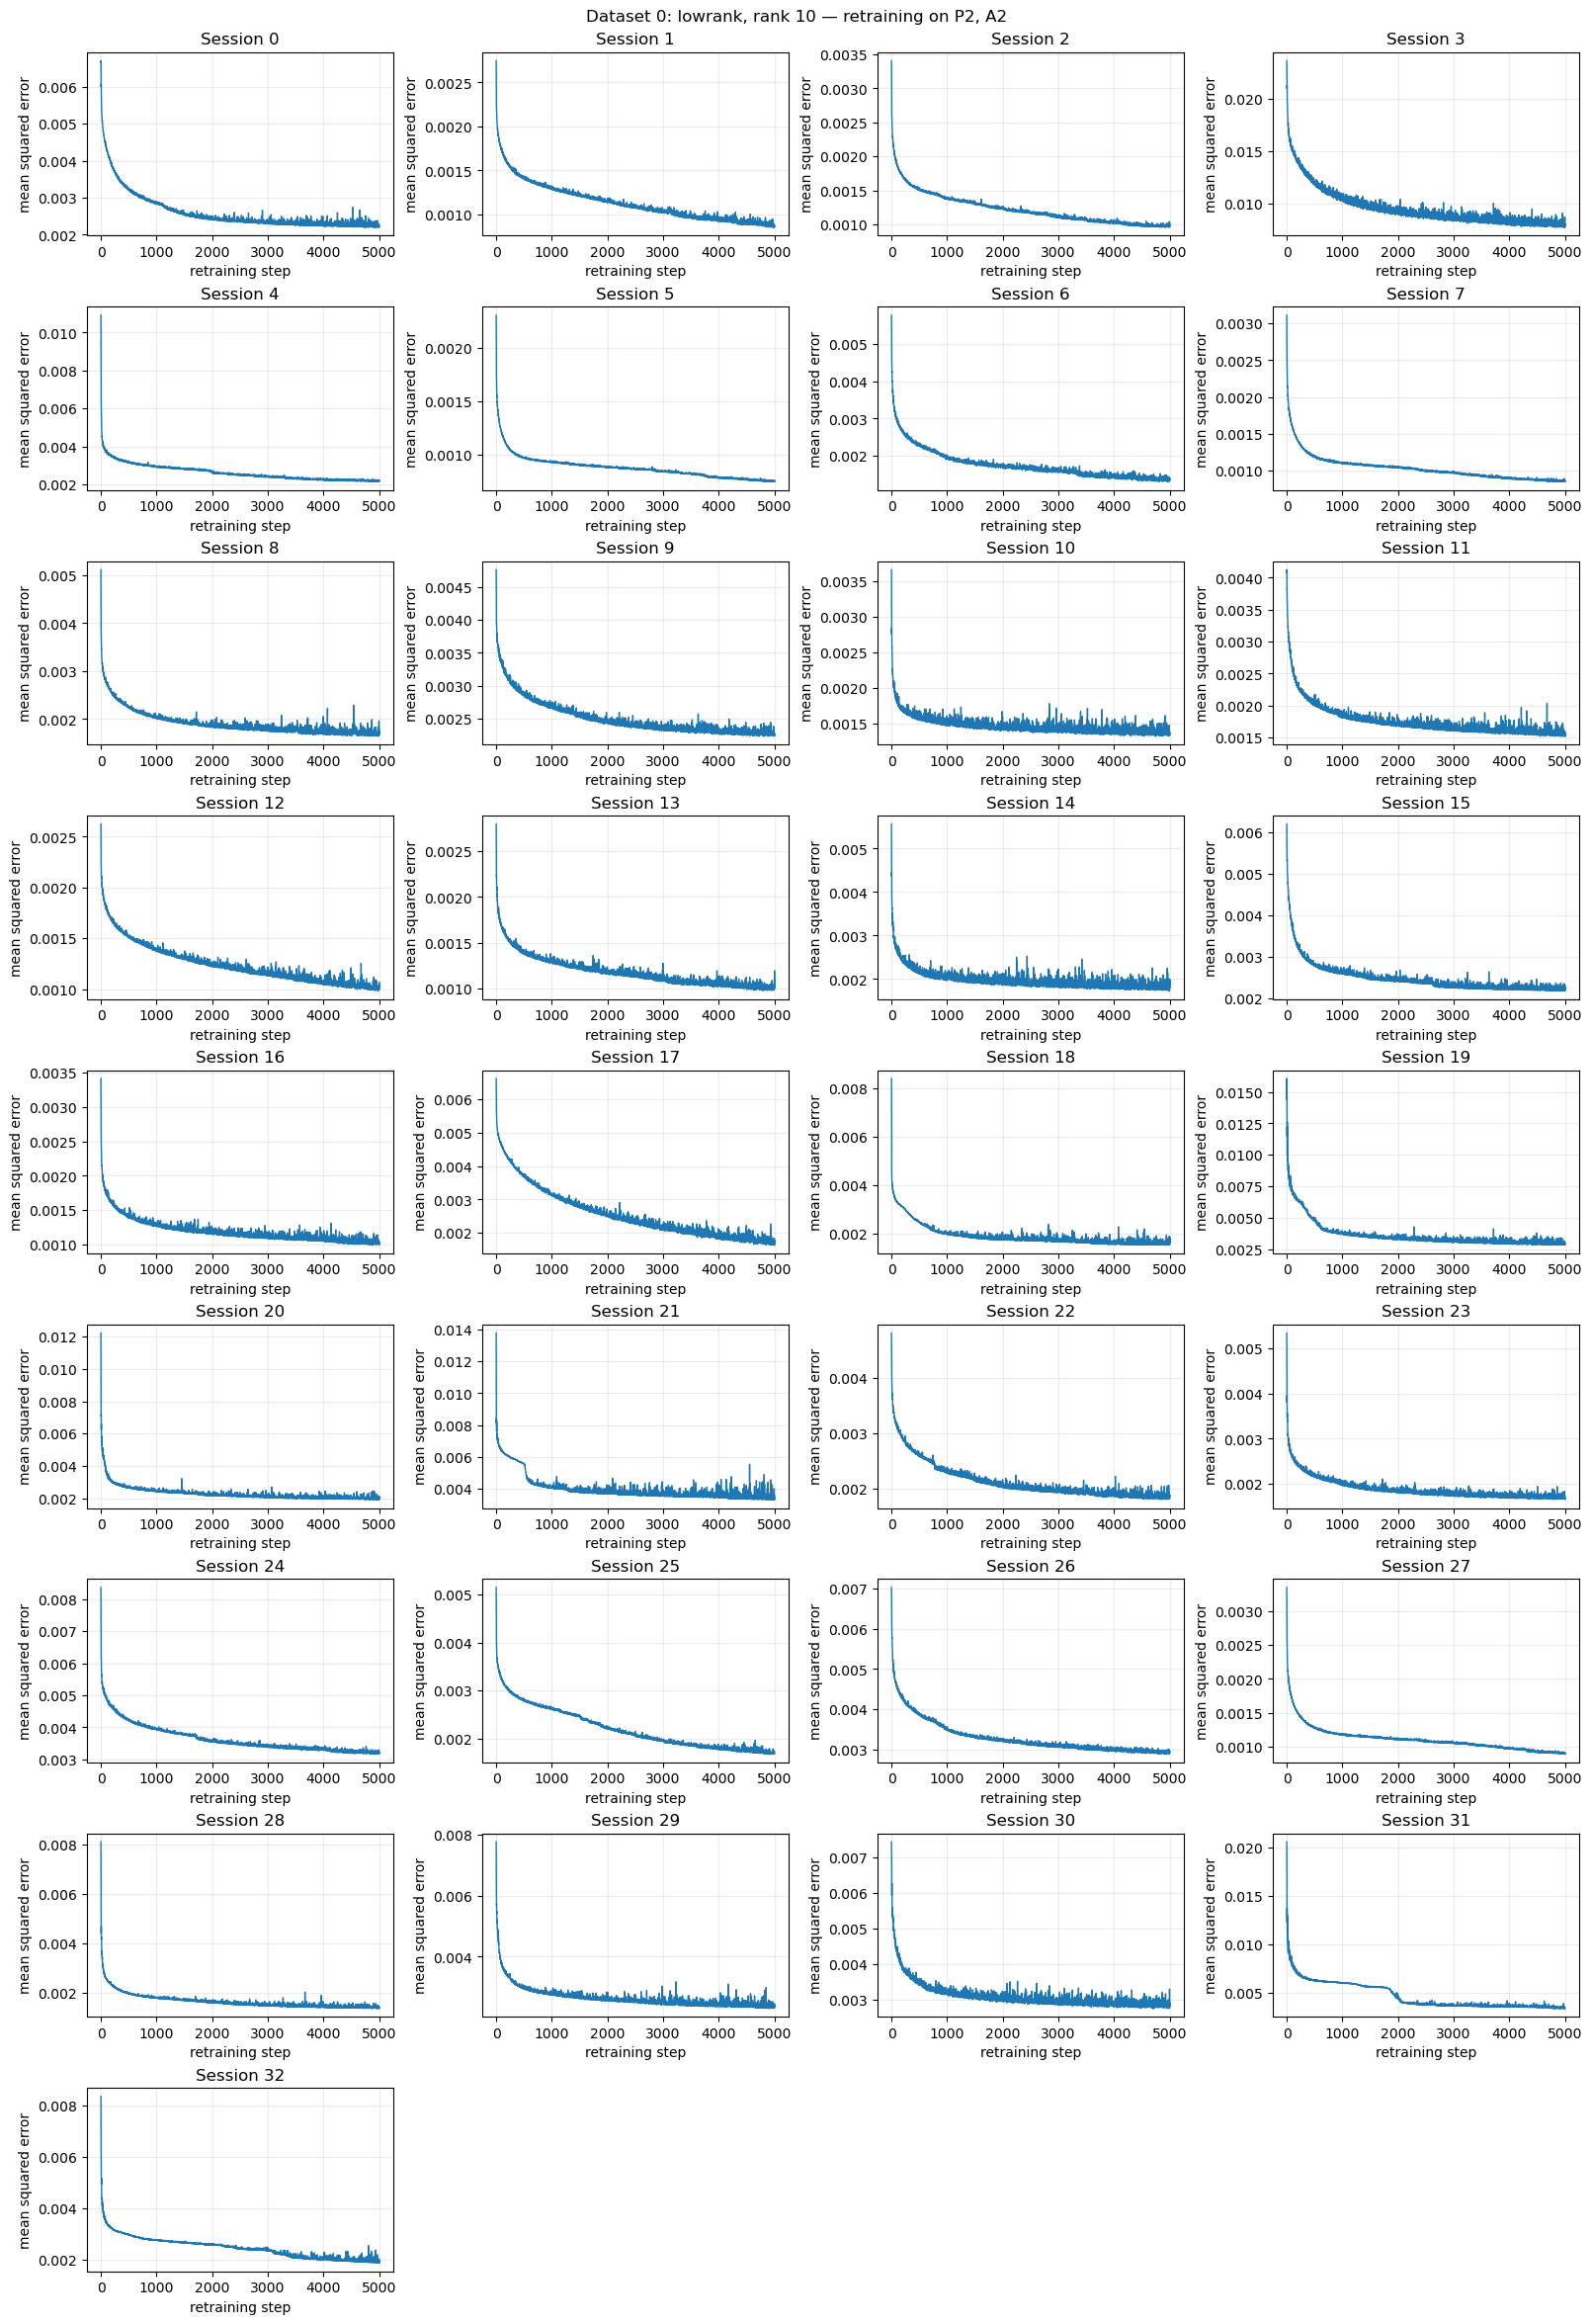

In [33]:
# One subplot per actual session ID; each curve is that session's own loss.
n_columns = min(4, n_sessions)
n_rows = int(np.ceil(n_sessions / n_columns))
fig, axes = plt.subplots(
    n_rows, n_columns, figsize=(4 * n_columns, 2.6 * n_rows),
    squeeze=False, layout='constrained',
)
for ax, fx in zip(axes.flat, rnn.session_ids):
    session_loss = np.asarray(loss_history_by_session[fx], dtype=float)
    ax.plot(np.arange(len(session_loss)), session_loss, linewidth=1)
    ax.set(
        title=f'Session {fx}',
        xlabel='retraining step',
        ylabel='mean squared error',
    )
    ax.grid(alpha=0.25)
for ax in axes.flat[n_sessions:]:
    ax.set_visible(False)
rank_label = f', rank {rnn.recurrent_rank}' if rnn.recurrent_type == 'lowrank' else ''
fig.suptitle(
    f'Dataset {dataset["id"]}: {rnn.recurrent_type}{rank_label} '
    f'— retraining on {", ".join(rnn.conditions)}'
)
plt.show()


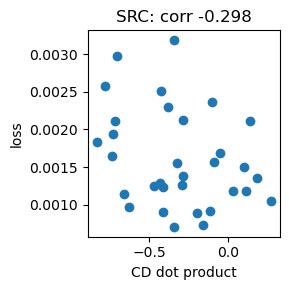

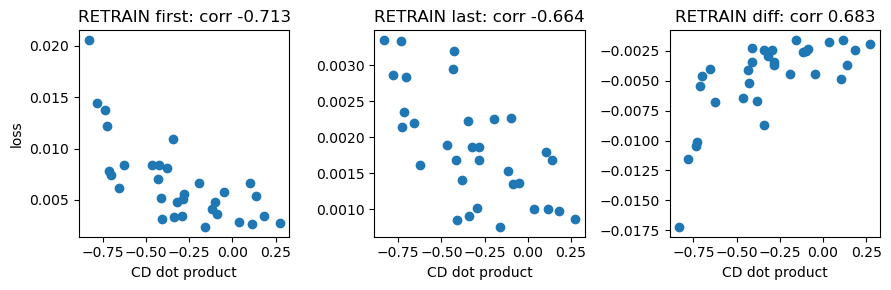

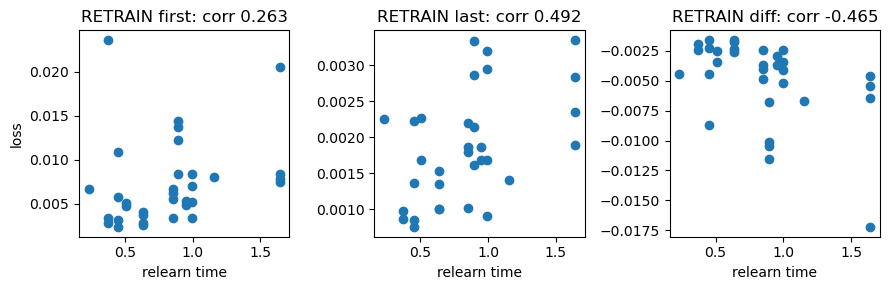

In [53]:
session_loss_src = np.zeros(33)
for fx in range(33):
    _loss_fx = np.asarray(loss_history_by_session_src[fx], dtype=float)
    session_loss_src[fx] = _loss_fx[-1]

plt.figure(figsize=(3,3))
idx = session_loss_src < 0.005
_cor = np.corrcoef(CDdotproduct[idx], session_loss_src[idx])[0,1]
plt.scatter(CDdotproduct[idx], session_loss_src[idx])
plt.title(f'SRC: corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product')
plt.ylabel('loss')
plt.tight_layout()


session_loss_first = np.zeros(33)
session_loss_last = np.zeros(33)
session_loss_diff = np.zeros(33)
for fx in range(33):
    _loss_fx = np.asarray(loss_history_by_session[fx], dtype=float)
    session_loss_first[fx] = _loss_fx[0]
    session_loss_last[fx]  = _loss_fx[-1]
    session_loss_diff[fx]  = _loss_fx[-1] - _loss_fx[0]

plt.figure(figsize=(9,3))
plt.subplot(131)
idx = session_loss_first < 0.022
_cor = np.corrcoef(CDdotproduct[idx], session_loss_first[idx])[0,1]
plt.scatter(CDdotproduct[idx], session_loss_first[idx])
plt.title(f'RETRAIN first: corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product')
plt.ylabel('loss')
plt.subplot(132)
idx = session_loss_last < 0.006
_cor = np.corrcoef(CDdotproduct[idx], session_loss_last[idx])[0,1]
plt.scatter(CDdotproduct[idx], session_loss_last[idx])
plt.title(f'RETRAIN last: corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product')
plt.subplot(133)
# idx = session_loss_last > -0.015
_cor = np.corrcoef(CDdotproduct[idx], session_loss_diff[idx])[0,1]
plt.scatter(CDdotproduct[idx], session_loss_diff[idx])
plt.title(f'RETRAIN diff: corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product')
plt.tight_layout()


plt.figure(figsize=(9,3))
plt.subplot(131)
idx = session_loss_first < 1
_cor = np.corrcoef(relearntime_sorted[idx], session_loss_first[idx])[0,1]
plt.scatter(relearntime_sorted[idx], session_loss_first[idx])
plt.title(f'RETRAIN first: corr {np.round(_cor,decimals=3)}')
plt.xlabel('relearn time')
plt.ylabel('loss')
plt.subplot(132)
idx = session_loss_last < 0.006
_cor = np.corrcoef(relearntime_sorted[idx], session_loss_last[idx])[0,1]
plt.scatter(relearntime_sorted[idx], session_loss_last[idx])
plt.title(f'RETRAIN last: corr {np.round(_cor,decimals=3)}')
plt.xlabel('relearn time')
plt.subplot(133)
# idx = session_loss_last > -0.015
_cor = np.corrcoef(relearntime_sorted[idx], session_loss_diff[idx])[0,1]
plt.scatter(relearntime_sorted[idx], session_loss_diff[idx])
plt.title(f'RETRAIN diff: corr {np.round(_cor,decimals=3)}')
plt.xlabel('relearn time')
plt.tight_layout()




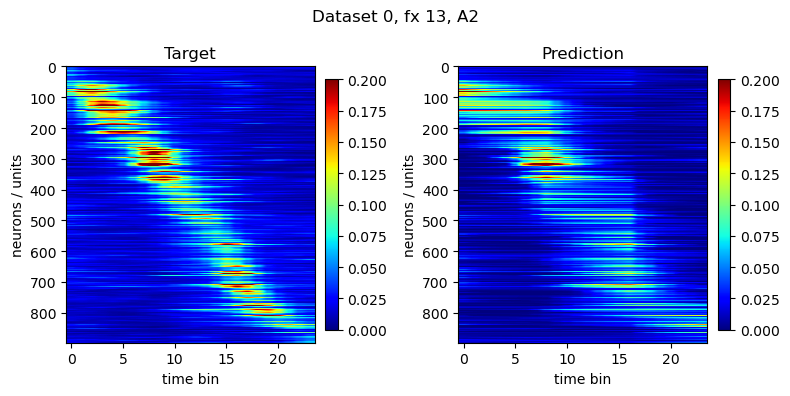

In [46]:
ln.plot_prediction_vs_target(
    results,
    fx=13,
    condition='A2',
)
plt.show()
